# Inference – model_pose

Same cell order and plots as the original inference notebook. Uses the learned pose output.

Set `GT_BINS_INPUT=False` for ordinary RGB model_pose runs. Set it to `True` only for checkpoints trained with `train_pose_gt_bins.py`; those runs use GT maps and have no trained vision output. Select the checkpoint directory below.


In [12]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

from dataset import SceneTwoPairsDataset
from model_pose import PairImageCylinderModel
from utils import plot_estimated_cylinders_on_images, plot_relative_pose, pose_to_text

# Match the architecture used during training.
IMG_SIZE = 128
PATCH_SIZE = (16, 4)
NUM_BINS = 128
EMBED_DIM = 192
DEPTH = 4
NUM_HEADS = 4
DROPOUT = 0.1

CHECKPOINT_DIR = Path("arrhenius_runs/slurm_pose_head_0/checkpoints/")

GT_BINS_INPUT = False  # True only for train_pose_gt_bins.py checkpoints

MODEL_VERSION = "best"  # "best" eller "latest"

CHECKPOINT = CHECKPOINT_DIR / f"{MODEL_VERSION}.pt"

TEST_DATASET = Path("valdataset")
INFERENCE_BATCH_SIZE = 4
VISION_SAMPLE_IDX = 0
INFERENCE_SHOW_TEXT = False
INFERENCE_SHOW_IMAGES = True
OCC_THRESHOLD = 0.2  # Same threshold used in train_v2 inference plots.

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_float32_matmul_precision("high")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Test dataset:", TEST_DATASET)


Device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
Test dataset: valdataset


In [13]:
import torch.nn.functional as F

def gt_bins_to_input(vision, image_size):
    """GT [occupancy, radius, depth, ID] -> three spatial input channels."""
    occupied = (vision[..., 0] > 0.5).float()
    radius = vision[..., 1].float().clamp_min(0)
    depth = vision[..., 2].float().clamp_min(0)
    features = torch.stack([
        occupied,
        torch.log1p(radius) * occupied,
        torch.log1p(depth) * occupied,
    ], dim=1).unsqueeze(2)
    return F.interpolate(features, size=(image_size, image_size), mode="nearest")


def predict_pose_from_gt_bins(model, vision_a, vision_b):
    patch_embed = model.backbone.patch_embed
    image_size = patch_embed.grid_h * patch_embed.patch_h
    input_a = gt_bins_to_input(vision_a, image_size)
    input_b = gt_bins_to_input(vision_b, image_size)
    camera_a, camera_b, patches_a, patches_b = model.backbone(input_a, input_b)
    return model.pose_head(camera_a, camera_b, patches_a, patches_b)


model = PairImageCylinderModel(
    img_size=IMG_SIZE,
    patch_size=PATCH_SIZE,
    in_chans=3,
    embed_dim=EMBED_DIM,
    depth=DEPTH,
    num_heads=NUM_HEADS,
    num_bins=NUM_BINS,
    dropout=DROPOUT,
).to(DEVICE)

checkpoint = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()
history = checkpoint.get("history")
print(f"Loaded checkpoint: {CHECKPOINT}")
print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")


Loaded checkpoint: arrhenius_runs/slurm_pose_head_0/checkpoints/best.pt
Checkpoint epoch: 20
Model parameters: 4,583,305


In [14]:
# Match train_v2 test dataset construction (no evaluation transform specified).
infer_dataset = SceneTwoPairsDataset(
    root_dir=str(TEST_DATASET),
    return_two_pairs=False,
)
infer_loader = DataLoader(
    infer_dataset,
    batch_size=INFERENCE_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)
print("Inference dataset size:", len(infer_dataset))


Inference dataset size: 482


In [4]:
batch = next(iter(infer_loader))
img_a, vision_a, img_b, vision_b, pose_ab = batch
img_a, vision_a = img_a.to(DEVICE), vision_a.to(DEVICE)
img_b, vision_b = img_b.to(DEVICE), vision_b.to(DEVICE)
pose_ab = pose_ab.to(DEVICE)

model.eval()
with torch.no_grad():
    if GT_BINS_INPUT:
        pred_pose = predict_pose_from_gt_bins(model, vision_a, vision_b)
        pred_vision = pred_vision_b = None
    else:
        pred_vision, pred_vision_b, pred_pose = model(img_a, img_b)

if not 0 <= VISION_SAMPLE_IDX < len(img_a):
    raise IndexError("VISION_SAMPLE_IDX is outside the inference batch")
if INFERENCE_SHOW_TEXT:
    for i in range(min(4, len(img_a))):
        print(f"Sample {i}")
        print("  GT   pose:", pose_to_text(pose_ab[i].detach().cpu()))
        print("  Pred pose:", pose_to_text(pred_pose[i].detach().cpu()))
        pose_err = torch.abs(pred_pose[i] - pose_ab[i]).detach().cpu()
        print(f"  |err|: tx={pose_err[0]:.3f}, ty={pose_err[1]:.3f}, sin={pose_err[2]:.3f}, cos={pose_err[3]:.3f}")
        print()
if pred_vision is not None:
    print("pred_vision shape:", pred_vision.shape)
print("pred_pose shape:", pred_pose.shape)
print("GT pose:", pose_ab[VISION_SAMPLE_IDX].detach().cpu())
print("Pred pose:", pred_pose[VISION_SAMPLE_IDX].detach().cpu())


pred_pose shape: torch.Size([4, 4])
GT pose: tensor([-0.3542,  0.9352, -0.0183,  0.9998])
Pred pose: tensor([-0.9983, -0.0576,  0.0024,  1.0000])


In [15]:
import torch

paths = {
    "vanlig": {
        10: "arrhenius_runs/slurm_old_model/checkpoints/epoch_010.pt",
        20: "arrhenius_runs/slurm_old_model/checkpoints/epoch_020.pt",
    },
    "pose0": {
        10: "arrhenius_runs/slurm_pose_head_0/checkpoints/epoch_010.pt",
        20: "arrhenius_runs/slurm_pose_head_0/checkpoints/epoch_020.pt",
    },
}

metrics = [
    ("loss", "val_total"),
    ("vision_loss", "val_vision"),
    ("correspondence_loss", "val_correspondence"),
    ("depth_structure_loss", "val_depth_structure"),
    ("depth_delta_loss", "val_depth_delta"),
]

for epoch in (10, 20):
    print(f"\nEpok {epoch}")
    for train_key, val_key in metrics:
        values = []
        for run in ("vanlig", "pose0"):
            ckpt = torch.load(
                paths[run][epoch],
                map_location="cpu",
                weights_only=False,
            )
            history = ckpt["history"]
            values.append(
                (history[train_key][-1], history[val_key][-1])
            )

        print(
            f"{train_key:24s} "
            f"vanlig train/val={values[0][0]:.4f}/{values[0][1]:.4f}  "
            f"pose0 train/val={values[1][0]:.4f}/{values[1][1]:.4f}"
        )


Epok 10
loss                     vanlig train/val=12.4289/12.3080  pose0 train/val=12.4283/12.3044
vision_loss              vanlig train/val=8.0135/7.9116  pose0 train/val=8.0116/7.9149
correspondence_loss      vanlig train/val=1.9606/1.9357  pose0 train/val=1.9605/1.9343
depth_structure_loss     vanlig train/val=4.3295/4.3092  pose0 train/val=4.3302/4.3116
depth_delta_loss         vanlig train/val=0.8288/0.8743  pose0 train/val=0.8317/0.8554

Epok 20
loss                     vanlig train/val=11.5232/11.4620  pose0 train/val=11.5350/11.5109
vision_loss              vanlig train/val=7.7392/7.6759  pose0 train/val=7.7482/7.7125
correspondence_loss      vanlig train/val=1.4071/1.3915  pose0 train/val=1.4090/1.4028
depth_structure_loss     vanlig train/val=4.0967/4.0946  pose0 train/val=4.1005/4.1178
depth_delta_loss         vanlig train/val=0.9386/0.9923  pose0 train/val=0.9359/0.9620


In [5]:
from metrics import evaluate_vision

if GT_BINS_INPUT:
    vision_metrics = None
    print("GT-bin run: vision heads were not trained; vision evaluation is skipped.")
else:
    vision_metrics = evaluate_vision(
        model,
        infer_loader,
        DEVICE,
        occ_threshold=OCC_THRESHOLD,
    )


GT-bin run: vision heads were not trained; vision evaluation is skipped.


In [6]:
@torch.no_grad()
def evaluate_pose(model, loader, device):
    model.eval()
    translation_errors, yaw_errors = [], []
    failures = total = 0
    for batch in loader:
        img_a, gt_a, img_b, gt_b, pose_gt = (
            x.to(device, non_blocking=True) for x in batch
        )
        if GT_BINS_INPUT:
            pose_pred = predict_pose_from_gt_bins(model, gt_a, gt_b)
        else:
            _, _, pose_pred = model(img_a, img_b)
        for pred, gt in zip(pose_pred, pose_gt):
            total += 1
            if (not torch.isfinite(pred).all()
                or torch.linalg.vector_norm(pred[:2]) < 1e-8
                or torch.linalg.vector_norm(gt[:2]) < 1e-8):
                failures += 1
                continue
            t_pred = F.normalize(pred[:2], dim=0)
            t_gt = F.normalize(gt[:2], dim=0)
            cos_t = torch.dot(t_pred, t_gt).clamp(-1.0, 1.0)
            translation_errors.append(torch.rad2deg(torch.acos(cos_t)).item())
            delta = torch.atan2(pred[2], pred[3]) - torch.atan2(gt[2], gt[3])
            yaw_errors.append(torch.rad2deg(torch.atan2(delta.sin(), delta.cos())).abs().item())
    t, yaw = np.asarray(translation_errors), np.asarray(yaw_errors)
    def stat(values, fn):
        return float(fn(values)) if len(values) else float("nan")
    print("CAMERA POSE PERFORMANCE")
    print("=" * 60)
    print(f"\nTest pairs:             {total}")
    print(f"Successful poses:       {len(t)}")
    print(f"Prediction failures:    {failures}")
    print(f"Success rate:           {len(t) / max(total, 1):.3f}")
    for label, values in [("TRANSLATION DIRECTION ERROR", t), ("YAW ERROR", yaw)]:
        print("\n" + label)
        print("-" * 40)
        print(f"Mean:                   {stat(values, np.mean):.2f}°")
        print(f"Median:                 {stat(values, np.median):.2f}°")
        print(f"P90:                    {stat(values, lambda x: np.percentile(x, 90)):.2f}°")
    print("\nACCURACY THRESHOLDS")
    print("-" * 40)
    for threshold in [5, 10, 20, 30]:
        t_acc = stat(t, lambda x: np.mean(x < threshold))
        yaw_acc = stat(yaw, lambda x: np.mean(x < threshold))
        print(f"< {threshold:2d}°: T={100*t_acc:5.1f}% | Yaw={100*yaw_acc:5.1f}%")
    return {
        "translation_errors": t, "yaw_errors": yaw,
        "failures": failures, "total": total,
        "translation_mean": stat(t, np.mean),
        "translation_median": stat(t, np.median),
        "translation_p90": stat(t, lambda x: np.percentile(x, 90)),
        "yaw_mean": stat(yaw, np.mean),
        "yaw_median": stat(yaw, np.median),
        "yaw_p90": stat(yaw, lambda x: np.percentile(x, 90)),
    }

pose_metrics = evaluate_pose(model, infer_loader, DEVICE)


CAMERA POSE PERFORMANCE

Test pairs:             482
Successful poses:       482
Prediction failures:    0
Success rate:           1.000

TRANSLATION DIRECTION ERROR
----------------------------------------
Mean:                   48.19°
Median:                 32.15°
P90:                    121.87°

YAW ERROR
----------------------------------------
Mean:                   3.79°
Median:                 2.35°
P90:                    9.66°

ACCURACY THRESHOLDS
----------------------------------------
<  5°: T= 25.3% | Yaw= 70.7%
< 10°: T= 33.6% | Yaw= 91.3%
< 20°: T= 43.4% | Yaw= 98.5%
< 30°: T= 49.2% | Yaw= 99.8%


## 1. Input image pair


In [7]:
# Plots are controlled by INFERENCE_SHOW_IMAGES in the following cells.


## 2. Vision prediction

Compare the predicted `(occupancy, radius, depth)` against the ground truth for image A.


In [8]:
sample_idx = VISION_SAMPLE_IDX
bins = np.arange(vision_a.shape[1])
PLOT_OCC_THRESHOLD = 0.2
if INFERENCE_SHOW_IMAGES and not GT_BINS_INPUT:
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    names = ["occupancy", "radius", "depth"]
    pr_occ = pred_vision[sample_idx, :, 0].detach().cpu().numpy()
    for j, ax in enumerate(axes):
        gt = vision_a[sample_idx, :, j].detach().cpu().numpy()
        pr = pred_vision[sample_idx, :, j].detach().cpu().numpy()
        ax.plot(bins, gt, label="GT", color="tab:blue")
        if j == 0:
            ax.plot(bins, pr, label="Pred", color="tab:orange")
        else:
            pr_mask = pr_occ > PLOT_OCC_THRESHOLD
            ax.scatter(bins[pr_mask], pr[pr_mask], label="Pred", color="tab:orange", s=25)
        ax.set_ylabel(names[j])
        ax.grid(True, alpha=0.3)
        ax.legend()
    axes[-1].set_xlabel("Bin")
    fig.suptitle(f"Vision prediction sample {sample_idx}")
    plt.tight_layout()
    plt.show()


## 3. Estimated cylinders and input images


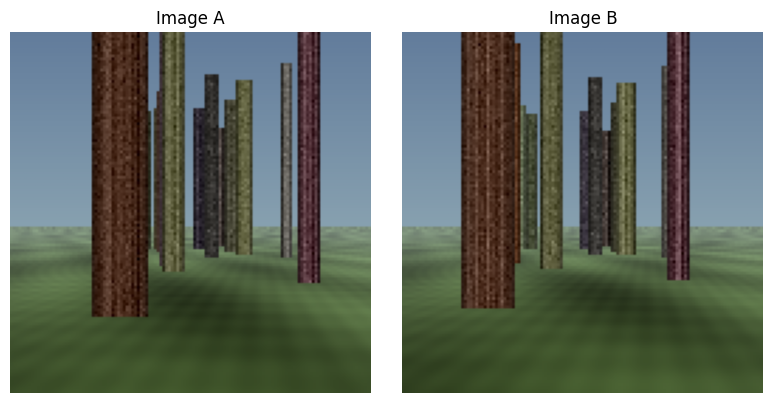

In [9]:
if INFERENCE_SHOW_IMAGES:
    if not GT_BINS_INPUT:
        fig_cyl, axes_cyl = plot_estimated_cylinders_on_images(
            [img_a[VISION_SAMPLE_IDX], img_b[VISION_SAMPLE_IDX]],
            [pred_vision[VISION_SAMPLE_IDX], pred_vision_b[VISION_SAMPLE_IDX]],
            titles=["Image A: pred cylinders", "Image B: pred cylinders"],
            occ_threshold=PLOT_OCC_THRESHOLD,
            flip_x=True,
        )
        plt.show()
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(img_a[VISION_SAMPLE_IDX].cpu().permute(1, 2, 0))
    axes[0].set_title("Image A")
    axes[0].axis("off")
    axes[1].imshow(img_b[VISION_SAMPLE_IDX].cpu().permute(1, 2, 0))
    axes[1].set_title("Image B")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()


## 4. Relative pose


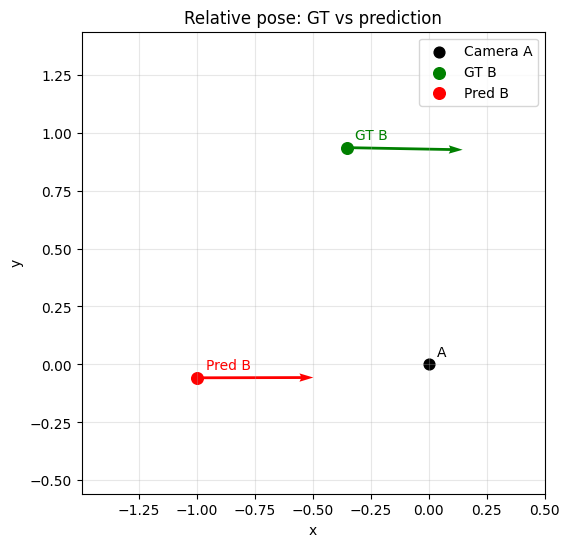

In [10]:
gt_pose = pose_ab[VISION_SAMPLE_IDX].detach().cpu()
pred_pose_sample = pred_pose[VISION_SAMPLE_IDX].detach().cpu()
if INFERENCE_SHOW_TEXT:
    print("GT :", pose_to_text(gt_pose))
    print("Pred:", pose_to_text(pred_pose_sample))
if INFERENCE_SHOW_IMAGES:
    plot_relative_pose(pose_ab[VISION_SAMPLE_IDX], pred_pose[VISION_SAMPLE_IDX])


## 5. Training history (optional)

Plot epoch-aligned loss curves stored in the selected checkpoint.


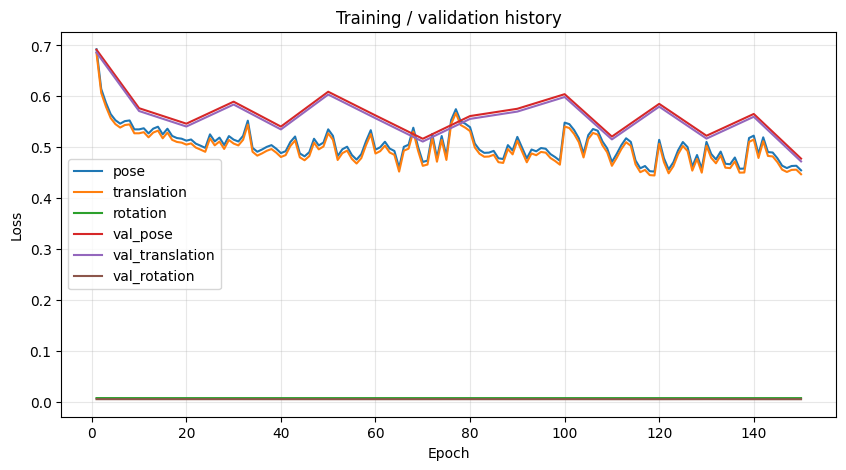

In [11]:
# train_v2 stores history as a dictionary of epoch-aligned metrics.
if isinstance(history, dict):
    epochs = history.get("epoch", [])
    val_epochs = history.get("val_epoch", [])
    train_keys = ["loss", "vision_loss", "pose_loss", "correspondence_loss", "pose", "translation", "rotation"]
    val_keys = ["val_total", "val_vision", "val_correspondence", "val_depth_structure", "val_depth_delta", "val_pose", "val_translation", "val_rotation"]
    plt.figure(figsize=(10, 5))
    plotted = False
    for keys, xs, prefix in [(train_keys, epochs, "train"), (val_keys, val_epochs, "val")]:
        for key in keys:
            ys = history.get(key, [])
            if len(xs) and len(ys) == len(xs):
                plt.plot(xs, ys, label=key)
                plotted = True
    if plotted:
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("Training / validation history")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()
    else:
        plt.close()
        print("History present, but no matching epoch-aligned loss curves.")
else:
    print("No training history stored in the selected checkpoint.")
